# MONTHLY AGGREGATION VERSION of NN, LSTM & GRU Forecasting — Rainfall Jakarta (2010-2026)
**Source:** NASA/POWER MERRA-2 | PRECTOTCORR (mm/day)

Notebook ini menjalankan model NN, LSTM, dan GRU untuk forecasting curah hujan.

Hasil evaluasi metrics dari notebook ini dimasukkan ke tabel perbandingan di R.


In [ ]:
# install dependencies
!pip install openpyxl -q

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

torch.manual_seed(42)
np.random.seed(42)

## 1. Load dan Preprocessing Data

In [ ]:
df = pd.read_excel('Dataset16Tahun.xlsx')
df["Date"] = pd.to_datetime(
    dict(
        year=df["YEAR"],
        month=df["MO"],
        day=df["DOY"]
    )
)
df = df.sort_values('Date').reset_index(drop=True)

print(df.shape)
df.head()

(5845, 5)


,YEAR,MO,DOY,PRECTOTCORR,Date
0,2010,1,1,0.82,2010-01-01
1,2010,1,2,6.52,2010-01-02
2,2010,1,3,3.46,2010-01-03
3,2010,1,4,3.20,2010-01-04
4,2010,1,5,3.82,2010-01-05


In [ ]:
monthly = (
    df.groupby(["YEAR", "MO"])["PRECTOTCORR"]
      .sum()
      .reset_index()
)

In [ ]:
monthly["Date"] = pd.to_datetime(
    monthly["YEAR"].astype(str) + "-" +
    monthly["MO"].astype(str) + "-01"
)

monthly = monthly.sort_values("Date")
monthly.head()

,YEAR,MO,PRECTOTCORR,Date
0,2010,1,391.26,2010-01-01
1,2010,2,296.75,2010-02-01
2,2010,3,284.74,2010-03-01
3,2010,4,70.94,2010-04-01
4,2010,5,197.50,2010-05-01


In [ ]:
# train-test split 80/20, urutan waktu
rain = monthly['PRECTOTCORR'].values.reshape(-1, 1)
n    = len(rain)
n_train = int(n * 0.8)
n_test  = n - n_train

train_raw = rain[:n_train]
test_raw  = rain[n_train:]

# scaler fit HANYA di training, lalu transform train dan test
# ini mencegah data leakage dari test ke training
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_raw)
test_scaled  = scaler.transform(test_raw)

print(f'Train: {n_train} months | Test: {n_test} months')

print("Train start:", monthly['Date'].iloc[0])
print("Train end  :", monthly['Date'].iloc[n_train-1])

print("Test start :", monthly['Date'].iloc[n_train])
print("Test end   :", monthly['Date'].iloc[-1])

Train: 154 months | Test: 39 months
Train start: 2010-01-01 00:00:00
Train end  : 2022-10-01 00:00:00
Test start : 2022-11-01 00:00:00
Test end   : 2026-01-01 00:00:00


In [ ]:
def create_sequences(data_scaled, full_scaled, seq_len, start_idx, n_samples):
    """Buat sliding window. Untuk test, context diambil dari akhir training."""
    context = full_scaled[start_idx - seq_len: start_idx]
    combined = np.concatenate([context, data_scaled])
    X, y = [], []
    for i in range(n_samples):
        X.append(combined[i: i + seq_len])
        y.append(combined[i + seq_len])
    return np.array(X), np.array(y)

full_scaled = np.concatenate([train_scaled, test_scaled])

In [ ]:
def evaluate_metrics(actual_scaled, pred_scaled, scaler, name):
    actual = scaler.inverse_transform(actual_scaled.reshape(-1, 1)).flatten()
    pred   = scaler.inverse_transform(pred_scaled.reshape(-1, 1)).flatten()
    rmse = np.sqrt(mean_squared_error(actual, pred))
    mae  = mean_absolute_error(actual, pred)
    mask = actual > 0
    mape  = np.mean(np.abs((actual[mask] - pred[mask]) / actual[mask])) * 100
    smape = np.mean(2 * np.abs(actual - pred) / (np.abs(actual) + np.abs(pred) + 1e-8)) * 100
    print(f'{name}: RMSE={rmse:.4f} | MAE={mae:.4f} | MAPE={mape:.2f}% | SMAPE={smape:.2f}%')
    return {'RMSE': round(rmse, 4), 'MAE': round(mae, 4),
            'MAPE': round(mape, 2), 'SMAPE': round(smape, 2),
            'actual': actual, 'pred': pred}

## 2. Neural Network (NN)

menggunakan lag bulanan sebagai input, lalu diproses lewat hidden layer non-linear.
Input lag ditentukan dari PACF yang signifikan. Dicoba berbagai kombinasi:
- Naikkan nodes dulu selama RMSE masih turun
- Tambah hidden layer kalau udah mentok


In [ ]:
SEQ_LEN_NN = 12
# alasan: dari PACF monthly, lag 1-3 umumnya signifikan
# 3 bulan = satu kuartal, secara praktis masuk akal untuk rainfall

X_train_nn, y_train_nn = create_sequences(train_scaled, full_scaled,
                                           SEQ_LEN_NN, n_train, n_train)
X_test_nn,  y_test_nn  = create_sequences(test_scaled,  full_scaled,
                                           SEQ_LEN_NN, n_train, n_test)
print(f'NN X_train: {X_train_nn.shape} | X_test: {X_test_nn.shape}')

NN X_train: (154, 12, 1) | X_test: (39, 12, 1)


In [ ]:
class NNModel(nn.Module):
    """Feedforward NN, bisa 1 atau 2 hidden layer."""
    def __init__(self, input_size, hidden_layers, dropout_rate=0.2):
        super(NNModel, self).__init__()
        layers = []
        prev = input_size
        for h in hidden_layers:
            layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout_rate)]
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x.squeeze(-1))


def train_nn(model, X_tr, y_tr, epochs=300, lr=0.001, batch_size=16,
             patience=30):
    """Training dengan early stopping."""
    # validation split dari training (10% terakhir)
    val_size  = max(1, int(len(X_tr) * 0.1))
    X_val, y_val = X_tr[-val_size:], y_tr[-val_size:]
    X_tr2, y_tr2 = X_tr[:-val_size], y_tr[:-val_size]

    dataset   = TensorDataset(torch.FloatTensor(X_tr2), torch.FloatTensor(y_tr2))
    loader    = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    best_val_loss = float('inf')
    wait = 0
    model.train()
    for epoch in range(epochs):
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb).squeeze(), yb.squeeze())
            loss.backward()
            optimizer.step()
        # cek validation loss
        model.eval()
        with torch.no_grad():
            val_pred = model(torch.FloatTensor(X_val)).squeeze().numpy()
            val_loss = mean_squared_error(y_val, val_pred)
        model.train()
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f'  Early stopping at epoch {epoch+1}')
                break
        if (epoch + 1) % 100 == 0:
            print(f'  Epoch {epoch+1} | val_loss: {val_loss:.6f}')

In [ ]:
# kombinasi hidden layer yang dicoba
# sesuai catatan: tambah nodes dulu, baru tambah hidden layer
nn_configs = [
    {'hidden': [16],       'label': 'NN(lag3, 1HL-16)'},
    {'hidden': [32],       'label': 'NN(lag3, 1HL-32)'},
    {'hidden': [64],       'label': 'NN(lag3, 1HL-64)'},
    {'hidden': [128],      'label': 'NN(lag3, 1HL-128)'},
    {'hidden': [64, 32],   'label': 'NN(lag3, 2HL-64,32)'},
    {'hidden': [128, 64],  'label': 'NN(lag3, 2HL-128,64)'},
]

nn_results = []
for cfg in nn_configs:
    print(f"Training {cfg['label']}...")
    torch.manual_seed(42)
    model = NNModel(input_size=SEQ_LEN_NN, hidden_layers=cfg['hidden'])
    train_nn(model, X_train_nn, y_train_nn, epochs=300)
    model.eval()
    with torch.no_grad():
        pred_test = model(torch.FloatTensor(X_test_nn)).squeeze().numpy()
    res = evaluate_metrics(y_test_nn, pred_test, scaler, cfg['label'])
    nn_results.append({'Model': cfg['label'], **{k: res[k] for k in ['RMSE','MAE','MAPE','SMAPE']}})

nn_df = pd.DataFrame(nn_results)
print('\n--- NN Summary ---')
print(nn_df.to_string(index=False))

Training NN(lag3, 1HL-16)...
  Early stopping at epoch 50
NN(lag3, 1HL-16): RMSE=102.1841 | MAE=77.8833 | MAPE=262.13% | SMAPE=51.51%
Training NN(lag3, 1HL-32)...
  Early stopping at epoch 41
NN(lag3, 1HL-32): RMSE=100.9870 | MAE=76.7627 | MAPE=326.01% | SMAPE=47.90%
Training NN(lag3, 1HL-64)...
  Early stopping at epoch 36
NN(lag3, 1HL-64): RMSE=101.2665 | MAE=74.7077 | MAPE=301.51% | SMAPE=46.50%
Training NN(lag3, 1HL-128)...
  Early stopping at epoch 36
NN(lag3, 1HL-128): RMSE=107.8785 | MAE=79.0656 | MAPE=299.23% | SMAPE=49.06%
Training NN(lag3, 2HL-64,32)...
  Early stopping at epoch 34
NN(lag3, 2HL-64,32): RMSE=108.3467 | MAE=81.3732 | MAPE=287.48% | SMAPE=49.00%
Training NN(lag3, 2HL-128,64)...
  Early stopping at epoch 35
NN(lag3, 2HL-128,64): RMSE=110.8413 | MAE=79.7466 | MAPE=291.24% | SMAPE=48.24%

--- NN Summary ---
               Model     RMSE     MAE   MAPE  SMAPE
    NN(lag3, 1HL-16) 102.1841 77.8833 262.13  51.51
    NN(lag3, 1HL-32) 100.9870 76.7627 326.01  47.90
    

Best NN: NN(lag3, 1HL-32)
  Early stopping at epoch 41
Best NN (test): RMSE=100.9870 | MAE=76.7627 | MAPE=326.01% | SMAPE=47.90%


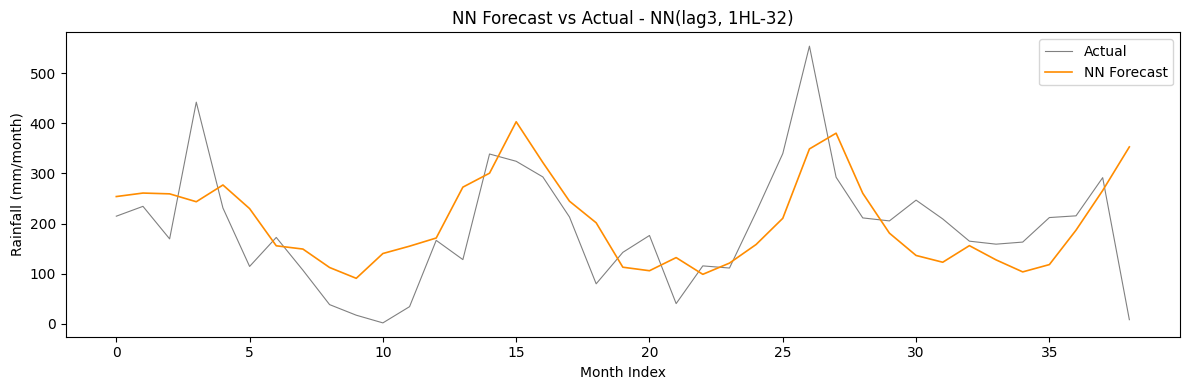

In [ ]:
# plot best NN
best_nn_idx = nn_df['RMSE'].idxmin()
best_nn_cfg = nn_configs[best_nn_idx]
print(f'Best NN: {best_nn_cfg["label"]}')

torch.manual_seed(42)
best_nn = NNModel(SEQ_LEN_NN, best_nn_cfg['hidden'])
train_nn(best_nn, X_train_nn, y_train_nn)
best_nn.eval()
with torch.no_grad():
    pred_nn = best_nn(torch.FloatTensor(X_test_nn)).squeeze().numpy()
res_nn = evaluate_metrics(y_test_nn, pred_nn, scaler, 'Best NN (test)')

plt.figure(figsize=(12, 4))
plt.plot(res_nn['actual'], color='grey', linewidth=0.8, label='Actual')
plt.plot(res_nn['pred'],   color='darkorange', linewidth=1.2, label='NN Forecast')
plt.title(f'NN Forecast vs Actual - {best_nn_cfg["label"]}')
plt.xlabel('Month Index'); plt.ylabel('Rainfall (mm/month)')
plt.legend(); plt.tight_layout(); plt.show()

## 4. LSTM
LSTM menggunakan sequence bulanan yang lebih panjang (6 bulan) karena LSTM
dirancang untuk menangkap long-term dependency.
Dropout diterapkan untuk mencegah overfitting pada dataset bulanan yang kecil.
Early stopping digunakan agar training berhenti saat validation loss tidak membaik.


In [ ]:
SEQ_LEN = 12  # 6 bulan = setengah tahun, cocok untuk tangkap pola seasonal

X_train_lstm, y_train_lstm = create_sequences(train_scaled, full_scaled,
                                               SEQ_LEN, n_train, n_train)
X_test_lstm,  y_test_lstm  = create_sequences(test_scaled,  full_scaled,
                                               SEQ_LEN, n_train, n_test)

X_train_t = torch.FloatTensor(X_train_lstm)
y_train_t = torch.FloatTensor(y_train_lstm)
X_test_t  = torch.FloatTensor(X_test_lstm)
y_test_t  = torch.FloatTensor(y_test_lstm)
print(f'LSTM/GRU X_train: {X_train_t.shape} | X_test: {X_test_t.shape}')

LSTM/GRU X_train: torch.Size([154, 12, 1]) | X_test: torch.Size([39, 12, 1])


In [ ]:
class RNNModel(nn.Module):
    def __init__(self, model_type, input_size, hidden_size, num_layers, dropout=0.2):
        super(RNNModel, self).__init__()
        rnn_dropout = dropout if num_layers > 1 else 0
        if model_type == 'LSTM':
            self.rnn = nn.LSTM(input_size, hidden_size, num_layers,
                               batch_first=True, dropout=rnn_dropout)
        elif model_type == 'GRU':
            self.rnn = nn.GRU(input_size, hidden_size, num_layers,
                              batch_first=True, dropout=rnn_dropout)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        out = self.dropout(out[:, -1, :])
        return self.fc(out)


def train_rnn(model, X_tr, y_tr, epochs=200, lr=0.001, batch_size=16, patience=25):
    """Training dengan early stopping untuk RNN."""
    val_size  = max(1, int(len(X_tr) * 0.1))
    X_val, y_val = X_tr[-val_size:], y_tr[-val_size:]
    X_tr2, y_tr2 = X_tr[:-val_size], y_tr[:-val_size]

    dataset   = TensorDataset(X_tr2, y_tr2)
    loader    = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    best_val = float('inf')
    wait = 0
    for epoch in range(epochs):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb).squeeze(), yb.squeeze())
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            val_pred = model(X_val).squeeze().numpy()
            val_loss = mean_squared_error(y_val.numpy(), val_pred)
        if val_loss < best_val:
            best_val = val_loss
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f'  Early stopping at epoch {epoch+1}')
                break
        if (epoch + 1) % 50 == 0:
            print(f'  Epoch {epoch+1} | val_loss: {val_loss:.6f}')

In [ ]:
# kombinasi hidden layer yang dicoba
lstm_configs = [
    {'hidden_size': 16,  'num_layers': 1, 'label': 'LSTM(16, 1L)'},
    {'hidden_size': 32,  'num_layers': 1, 'label': 'LSTM(32, 1L)'},
    {'hidden_size': 64,  'num_layers': 1, 'label': 'LSTM(64, 1L)'},
    {'hidden_size': 128, 'num_layers': 1, 'label': 'LSTM(128, 1L)'},
    {'hidden_size': 32,  'num_layers': 2, 'label': 'LSTM(32, 2L)'},
    {'hidden_size': 64,  'num_layers': 2, 'label': 'LSTM(64, 2L)'},
]

lstm_results = []
for cfg in lstm_configs:
    print(f"\nTraining {cfg['label']}...")
    torch.manual_seed(42)
    model = RNNModel('LSTM', 1, cfg['hidden_size'], cfg['num_layers'])
    train_rnn(model, X_train_t, y_train_t)
    model.eval()
    with torch.no_grad():
        pred_test = model(X_test_t).squeeze().numpy()
    res = evaluate_metrics(y_test_t.numpy(), pred_test, scaler, cfg['label'])
    lstm_results.append({'Model': cfg['label'], **{k: res[k] for k in ['RMSE','MAE','MAPE','SMAPE']}})

lstm_df = pd.DataFrame(lstm_results)
print('\n--- LSTM Summary ---')
print(lstm_df.to_string(index=False))


Training LSTM(16, 1L)...
  Epoch 50 | val_loss: 0.005206
  Early stopping at epoch 61
LSTM(16, 1L): RMSE=92.4513 | MAE=72.7008 | MAPE=267.07% | SMAPE=47.49%

Training LSTM(32, 1L)...
  Epoch 50 | val_loss: 0.013421
  Early stopping at epoch 53
LSTM(32, 1L): RMSE=90.0647 | MAE=66.8224 | MAPE=251.42% | SMAPE=45.59%

Training LSTM(64, 1L)...
  Early stopping at epoch 41
LSTM(64, 1L): RMSE=91.7507 | MAE=67.9283 | MAPE=265.07% | SMAPE=44.94%

Training LSTM(128, 1L)...
  Early stopping at epoch 38
LSTM(128, 1L): RMSE=91.3625 | MAE=67.8895 | MAPE=275.72% | SMAPE=44.82%

Training LSTM(32, 2L)...
  Early stopping at epoch 47
LSTM(32, 2L): RMSE=91.7589 | MAE=67.4344 | MAPE=285.12% | SMAPE=44.41%

Training LSTM(64, 2L)...
  Early stopping at epoch 42
LSTM(64, 2L): RMSE=93.5276 | MAE=68.9974 | MAPE=304.67% | SMAPE=44.89%

--- LSTM Summary ---
        Model    RMSE     MAE       MAPE     SMAPE
 LSTM(16, 1L) 92.4513 72.7008 267.070007 47.490002
 LSTM(32, 1L) 90.0647 66.8224 251.419998 45.590000
 LS

Best LSTM: LSTM(32, 1L)
  Epoch 50 | val_loss: 0.013421
  Early stopping at epoch 53
Best LSTM (test): RMSE=90.0647 | MAE=66.8224 | MAPE=251.42% | SMAPE=45.59%


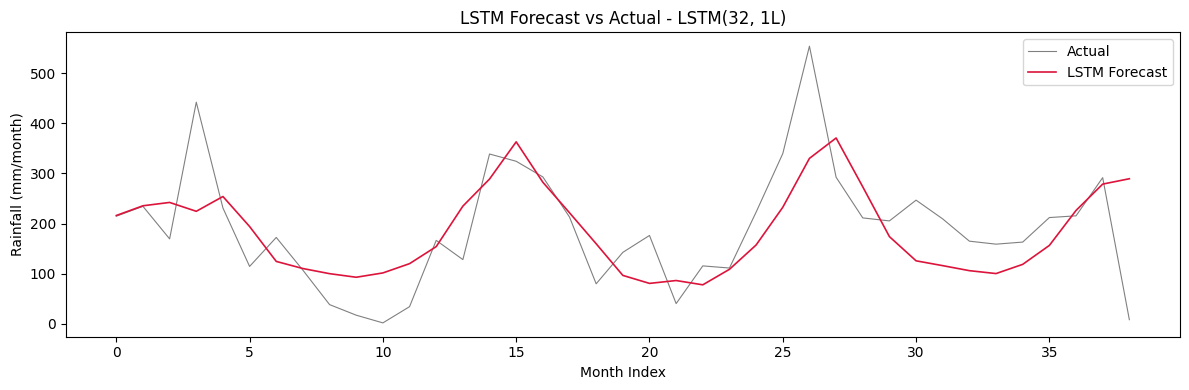

In [ ]:
# retrain best LSTM untuk plot
best_lstm_idx = lstm_df['RMSE'].idxmin()
best_lstm_cfg = lstm_configs[best_lstm_idx]
print(f'Best LSTM: {best_lstm_cfg["label"]}')

torch.manual_seed(42)
best_lstm = RNNModel('LSTM', 1, best_lstm_cfg['hidden_size'], best_lstm_cfg['num_layers'])
train_rnn(best_lstm, X_train_t, y_train_t)
best_lstm.eval()
with torch.no_grad():
    pred_lstm = best_lstm(X_test_t).squeeze().numpy()
res_lstm = evaluate_metrics(y_test_t.numpy(), pred_lstm, scaler, 'Best LSTM (test)')

plt.figure(figsize=(12, 4))
plt.plot(res_lstm['actual'], color='grey', linewidth=0.8, label='Actual')
plt.plot(res_lstm['pred'],   color='crimson', linewidth=1.2, label='LSTM Forecast')
plt.title(f'LSTM Forecast vs Actual - {best_lstm_cfg["label"]}')
plt.xlabel('Month Index'); plt.ylabel('Rainfall (mm/month)')
plt.legend(); plt.tight_layout(); plt.show()

## 5. GRU

GRU adalah versi yang lebih efisien dari LSTM.
Menggunakan sequence length yang sama (6 bulan) agar perbandingan fair.
Karena parameter lebih sedikit, GRU lebih cepat dan sering menghindari overfitting
pada dataset kecil seperti data bulanan 6 tahun ini.

In [ ]:
gru_configs = [
    {'hidden_size': 16,  'num_layers': 1, 'label': 'GRU(16, 1L)'},
    {'hidden_size': 32,  'num_layers': 1, 'label': 'GRU(32, 1L)'},
    {'hidden_size': 64,  'num_layers': 1, 'label': 'GRU(64, 1L)'},
    {'hidden_size': 128, 'num_layers': 1, 'label': 'GRU(128, 1L)'},
    {'hidden_size': 32,  'num_layers': 2, 'label': 'GRU(32, 2L)'},
    {'hidden_size': 64,  'num_layers': 2, 'label': 'GRU(64, 2L)'},
]

gru_results = []
for cfg in gru_configs:
    print(f"\nTraining {cfg['label']}...")
    torch.manual_seed(42)
    model = RNNModel('GRU', 1, cfg['hidden_size'], cfg['num_layers'])
    train_rnn(model, X_train_t, y_train_t)
    model.eval()
    with torch.no_grad():
        pred_test = model(X_test_t).squeeze().numpy()
    res = evaluate_metrics(y_test_t.numpy(), pred_test, scaler, cfg['label'])
    gru_results.append({'Model': cfg['label'], **{k: res[k] for k in ['RMSE','MAE','MAPE','SMAPE']}})

gru_df = pd.DataFrame(gru_results)
print('\n--- GRU Summary ---')
print(gru_df.to_string(index=False))


Training GRU(16, 1L)...
  Epoch 50 | val_loss: 0.004543
  Early stopping at epoch 98
GRU(16, 1L): RMSE=94.5691 | MAE=74.3992 | MAPE=261.44% | SMAPE=47.45%

Training GRU(32, 1L)...
  Epoch 50 | val_loss: 0.004727
  Early stopping at epoch 57
GRU(32, 1L): RMSE=92.4024 | MAE=73.1140 | MAPE=257.01% | SMAPE=47.18%

Training GRU(64, 1L)...
  Early stopping at epoch 45
GRU(64, 1L): RMSE=90.6670 | MAE=68.3259 | MAPE=250.70% | SMAPE=45.27%

Training GRU(128, 1L)...
  Early stopping at epoch 36
GRU(128, 1L): RMSE=91.9444 | MAE=70.3390 | MAPE=228.75% | SMAPE=46.97%

Training GRU(32, 2L)...
  Epoch 50 | val_loss: 0.004057
  Early stopping at epoch 51
GRU(32, 2L): RMSE=93.7940 | MAE=72.9305 | MAPE=263.81% | SMAPE=47.12%

Training GRU(64, 2L)...
  Early stopping at epoch 39
GRU(64, 2L): RMSE=92.5349 | MAE=71.3098 | MAPE=274.04% | SMAPE=44.88%

--- GRU Summary ---
       Model    RMSE     MAE       MAPE     SMAPE
 GRU(16, 1L) 94.5691 74.3992 261.440002 47.450001
 GRU(32, 1L) 92.4024 73.1140 257.0100

Best GRU: GRU(64, 1L)
  Early stopping at epoch 45
Best GRU (test): RMSE=90.6670 | MAE=68.3259 | MAPE=250.70% | SMAPE=45.27%


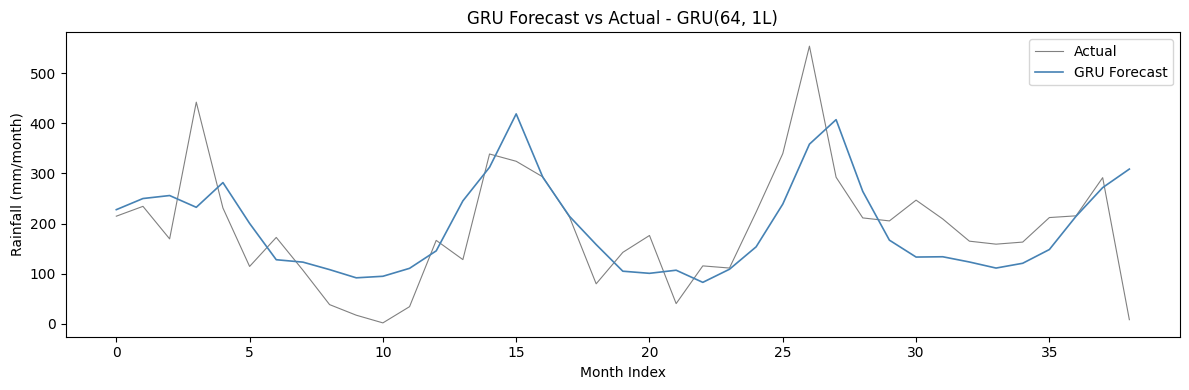

In [ ]:
best_gru_idx = gru_df['RMSE'].idxmin()
best_gru_cfg = gru_configs[best_gru_idx]
print(f'Best GRU: {best_gru_cfg["label"]}')

torch.manual_seed(42)
best_gru = RNNModel('GRU', 1, best_gru_cfg['hidden_size'], best_gru_cfg['num_layers'])
train_rnn(best_gru, X_train_t, y_train_t)
best_gru.eval()
with torch.no_grad():
    pred_gru = best_gru(X_test_t).squeeze().numpy()
res_gru = evaluate_metrics(y_test_t.numpy(), pred_gru, scaler, 'Best GRU (test)')

plt.figure(figsize=(12, 4))
plt.plot(res_gru['actual'], color='grey', linewidth=0.8, label='Actual')
plt.plot(res_gru['pred'],   color='steelblue', linewidth=1.2, label='GRU Forecast')
plt.title(f'GRU Forecast vs Actual - {best_gru_cfg["label"]}')
plt.xlabel('Month Index'); plt.ylabel('Rainfall (mm/month)')
plt.legend(); plt.tight_layout(); plt.show()

## 5. Summary — Nilai untuk dimasukkan ke R Markdown

In [ ]:
print(f'rmse_nn_test   <- {res_nn["RMSE"]}')
print(f'mae_nn_test    <- {res_nn["MAE"]}')
print(f'mape_nn_test   <- {res_nn["MAPE"]}')
print(f'rmse_lstm_test <- {res_lstm["RMSE"]}')
print(f'mae_lstm_test  <- {res_lstm["MAE"]}')
print(f'mape_lstm_test <- {res_lstm["MAPE"]}')
print(f'rmse_gru_test  <- {res_gru["RMSE"]}')
print(f'mae_gru_test   <- {res_gru["MAE"]}')
print(f'mape_gru_test  <- {res_gru["MAPE"]}')
print()
print('Detail NN:') ; print(nn_df.to_string(index=False))
print('\nDetail LSTM:') ; print(lstm_df.to_string(index=False))
print('\nDetail GRU:')  ; print(gru_df.to_string(index=False))

rmse_nn_test   <- 100.987
mae_nn_test    <- 76.7627
mape_nn_test   <- 326.01
rmse_lstm_test <- 90.0647
mae_lstm_test  <- 66.8224
mape_lstm_test <- 251.4199981689453
rmse_gru_test  <- 90.667
mae_gru_test   <- 68.3259
mape_gru_test  <- 250.6999969482422

Detail NN:
               Model     RMSE     MAE   MAPE  SMAPE
    NN(lag3, 1HL-16) 102.1841 77.8833 262.13  51.51
    NN(lag3, 1HL-32) 100.9870 76.7627 326.01  47.90
    NN(lag3, 1HL-64) 101.2665 74.7077 301.51  46.50
   NN(lag3, 1HL-128) 107.8785 79.0656 299.23  49.06
 NN(lag3, 2HL-64,32) 108.3467 81.3732 287.48  49.00
NN(lag3, 2HL-128,64) 110.8413 79.7466 291.24  48.24

Detail LSTM:
        Model    RMSE     MAE       MAPE     SMAPE
 LSTM(16, 1L) 92.4513 72.7008 267.070007 47.490002
 LSTM(32, 1L) 90.0647 66.8224 251.419998 45.590000
 LSTM(64, 1L) 91.7507 67.9283 265.070007 44.939999
LSTM(128, 1L) 91.3625 67.8895 275.720001 44.820000
 LSTM(32, 2L) 91.7589 67.4344 285.119995 44.410000
 LSTM(64, 2L) 93.5276 68.9974 304.670013 44.889999

